# Q-switching and mode-locking: nanosecond and femtosecond pulses

A continuous laser spends its energy as fast as the pump delivers it.
Pulsed lasers store it first and release it at once. **Q-switching**
stores it in the inversion: the resonator is kept lossy (low quality
factor Q) while the pump fills the upper level far above threshold, then
the loss is switched off, and the stored energy leaves in a giant pulse of
some nanoseconds and up to megawatts. **Mode-locking** stores it in the
resonator itself: a single short pulse circulates, and the output is a
train of pulses at the round trip rate, as short as the gain bandwidth
allows, picoseconds to a few femtoseconds. Seen in frequency, the
mode-locked laser is a comb of equally spaced, phase locked modes.

This notebook builds on the rate equations and the modes of notebook 142
(laser fundamentals), with the `lasers` module:

1. active Q-switching: the giant pulse from the rate equations and the
   Wagner–Birnbaum solution,
2. repetitively Q-switched lasers: energy, peak and average power against
   the repetition rate,
3. passive Q-switching with a saturable absorber,
4. mode-locking as phase locked modes, the pulse train and the frequency
   comb,
5. active mode-locking with a modulator: Haus's master equation against
   Kuizenga and Siegman,
6. passive mode-locking with a fast saturable absorber, and soliton
   mode-locking with dispersion and self-phase modulation.

The pulses themselves, their dispersion in lenses and their measurement,
are the subject of notebook 81 (ultrashort pulses).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import lasers as L
from pyoptics import sketch
from pyoptics.ultrafast import fwhm

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

## 1. Active Q-switching

The laser is a diode pumped Nd:YAG rod in a 25 cm resonator with a 20 %
output coupler and 4 % internal loss per round trip: photon lifetime
6.3 ns. A Pockels cell between a polarizer and the end mirror (notebook
139, electro-optic modulators) rotates the polarization by 90° per round
trip while its voltage is on, so that the polarizer throws the light out:
the loss is 50 times the normal cavity loss and the laser cannot start.
The pump, held five times above the threshold of the open cavity, raises
the inversion with the upper level lifetime $\tau$ = 230 µs. After 250 µs
the voltage drops in a few nanoseconds.

The normalized rate equations of notebook 142 (laser fundamentals) with
the inversion $n$ (in units of the threshold inversion of the open
cavity) and a time dependent loss $q(t)$ describe the pulse. During its
build-up and release the pump and the spontaneous decay hardly matter,
and the rate equations integrate to the **Wagner–Birnbaum** solution:
the final inversion $n_f$ follows from the initial $n_i$ by

$$n_i - n_f = \ln\frac{n_i}{n_f},$$

the fraction $(n_i - n_f)/n_i$ of the stored inversion is extracted, and
the peak photon number is $N_{th}(n_i - 1 - \ln n_i)$. The pulse
reaches its peak when the inversion has fallen to threshold, $n = 1$, and
the photons left in the cavity then take the remaining inversion down to
$n_f < 1$.

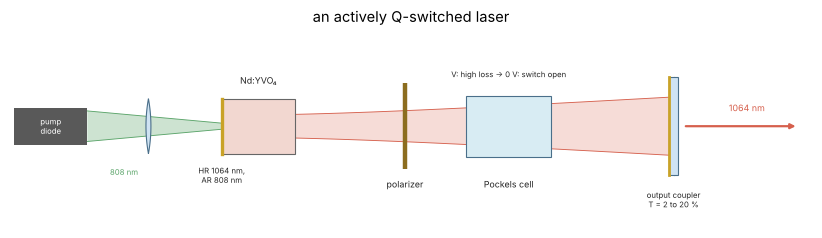

photon lifetime 6.34 ns, round trip 1.67 ns, threshold inversion 2.36e+15 ions


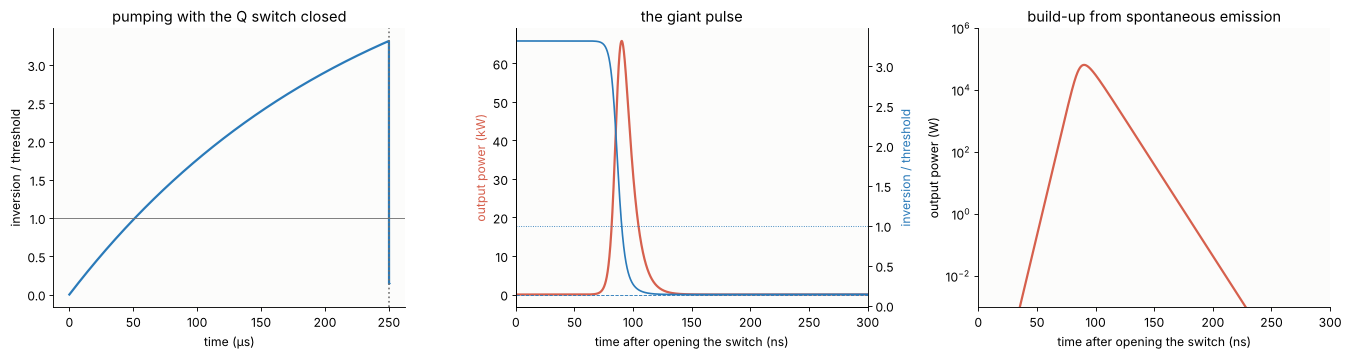

initial inversion n_i = 3.314 (r (1 − exp(−t/tau)) = 3.314)
simulated: final inversion 0.1425, peak 65.8 kW at 90 ns, FWHM 15.5 ns, energy 1.188 mJ
Wagner-Birnbaum: final inversion 0.1384, peak 65.8 kW, energy/peak 18.0 ns, energy 1.187 mJ


In [2]:
fig, ax = plt.subplots(figsize=(13, 3.6))
sketch.laser_layout(ax, "q_switched", title="an actively Q-switched laser")
plt.show()

yag = L.GAIN_MEDIA["Nd:YAG"]
tau, sigma, wl = yag["tau"], yag["sigma"], yag["wavelength"]
h_nu = L.photon_energy(wl)
L_cav, T_oc, delta_i, w_mode = 0.25, 0.20, 0.04, 0.4E-3
T_log = -np.log(1 - T_oc)
delta = T_log + delta_i
tau_c = 2*L_cav/(L.C0*delta)
T_rt = 2*L_cav/L.C0
A_mode = np.pi*w_mode**2
N_th = delta*A_mode/(2*sigma)        # inverted ions at threshold (gain medium of any length)
print("photon lifetime {:.2f} ns, round trip {:.2f} ns, threshold inversion {:.2e} ions".format(
    tau_c*1E9, T_rt*1E9, N_th))


def pulse_energy(n_i, n_f):
    """output energy (J): the photons from the extracted inversion that leave through the coupler"""
    return h_nu*N_th*(n_i - n_f)*T_log/delta


def peak_power(p_peak):
    """output peak power (W) for the peak photon number p_peak (units of N_th)"""
    return h_nu*p_peak*N_th*T_log/T_rt


r, hold, q_closed = 5.0, 250E-6, 50.0
t = np.concatenate([np.linspace(0, hold, 2001)[:-1], hold + np.linspace(0, 300E-9, 60001)])
n, p = L.rate_equations(t, r, tau, tau_c, beta=1E-9, loss=lambda tt: q_closed if tt < hold else 1.0,
                        max_step=1E-9)
P_out = h_nu*p*N_th*tau_c/tau*T_log/T_rt     # p is in units of N_th tau_c/tau
k_sw = np.searchsorted(t, hold)
n_i = n[k_sw]
qs = L.q_switch(n_i, tau_c)
dt_pulse = t[k_sw:]
E_sim = np.trapezoid(P_out[k_sw:], t[k_sw:])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
ax.plot(t*1E6, n, color=BLUE, lw=2)
ax.axvline(hold*1E6, color=GREY, ls=":")
ax.axhline(1, color=GREY, lw=0.8)
ax.set_xlabel("time (µs)"); ax.set_ylabel("inversion / threshold")
ax.set_title("pumping with the Q switch closed")
ax = axes[1]
tp = (t[k_sw:] - hold)*1E9
ax.plot(tp, P_out[k_sw:]/1E3, color=RED, lw=2, label="output power (kW)")
ax2 = ax.twinx()
ax2.plot(tp, n[k_sw:], color=BLUE, lw=1.5, label="inversion")
ax2.axhline(1, color=BLUE, lw=0.8, ls=":")
ax2.axhline(qs["n_f"], color=BLUE, lw=0.8, ls="--")
ax2.set_ylabel("inversion / threshold", color=BLUE)
ax2.spines["right"].set_visible(True)
ax.set_xlabel("time after opening the switch (ns)"); ax.set_ylabel("output power (kW)", color=RED)
ax.set_title("the giant pulse")
ax.set_xlim(0, 300)
ax = axes[2]
ax.semilogy(tp, np.maximum(P_out[k_sw:], 1E-6), color=RED, lw=2)
ax.set_xlabel("time after opening the switch (ns)"); ax.set_ylabel("output power (W)")
ax.set_title("build-up from spontaneous emission")
ax.set_xlim(0, 300); ax.set_ylim(1E-3, 1E6)
plt.tight_layout()
plt.show()

k_pk = np.argmax(P_out)
print("initial inversion n_i = {:.3f} (r (1 − exp(−t/tau)) = {:.3f})".format(n_i, r*(1 - np.exp(-hold/tau))))
print("simulated: final inversion {:.4f}, peak {:.1f} kW at {:.0f} ns, FWHM {:.1f} ns, energy {:.3f} mJ".format(
    n[-1], P_out.max()/1E3, (t[k_pk] - hold)*1E9, fwhm(t[k_sw:], P_out[k_sw:])*1E9, E_sim*1E3))
print("Wagner-Birnbaum: final inversion {:.4f}, peak {:.1f} kW, energy/peak {:.1f} ns, energy {:.3f} mJ".format(
    qs["n_f"], peak_power(qs["p_peak"])/1E3, qs["width"]*1E9, pulse_energy(n_i, qs["n_f"])*1E3))

The inversion climbs to 3.3 times threshold in 250 µs. After the switch
opens, the photons need 90 ns to grow from spontaneous emission to the
peak, about 15 photon lifetimes for 17 decades of growth at a net gain of
$(n_i - 1)/\tau_c$ per unit time. The pulse takes 96 % of the inversion
in 16 ns (FWHM): 1.2 mJ at 66 kW peak power, from a laser that would
deliver 6.5 W continuously. Peak power and energy of the simulation and
the Wagner–Birnbaum formulas agree to better than a percent, the final
inversion within 3 % (the pump keeps pumping during the pulse); the pulse is
asymmetric, with a steep rise while the gain is high and a tail at the
photon lifetime once the gain is gone.

How the pulse scales with the initial inversion follows from the same
formulas: the extraction efficiency approaches 1 above $n_i \approx 3$,
the energy grows linearly with $n_i$, and the peak power faster, because
the pulse becomes shorter, approaching a few photon lifetimes.

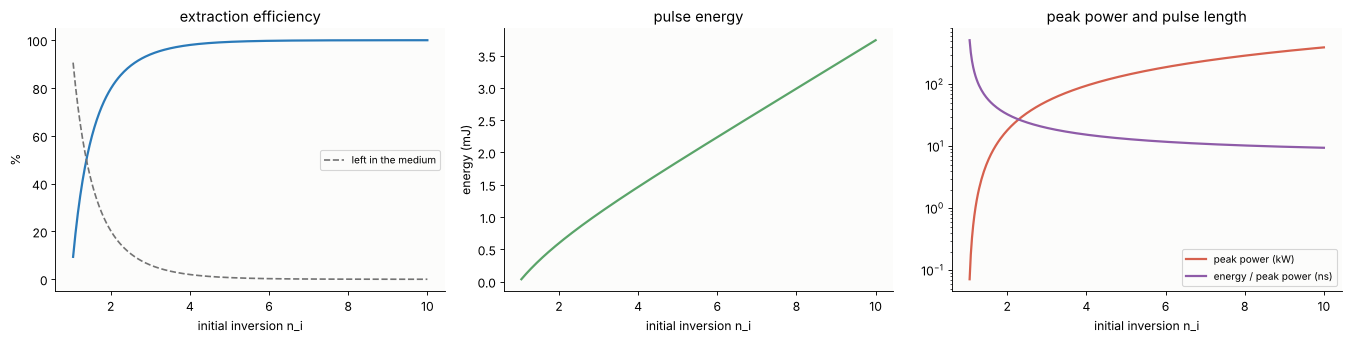

n_i = 1.5: 58.3 % extracted, 0.33 mJ,    5.6 kW, 58.6 ns
n_i = 3.0: 94.0 % extracted, 1.05 mJ,   53.2 kW, 19.8 ns
n_i = 8.0: 100.0 % extracted, 2.99 mJ,  290.3 kW, 10.3 ns


In [3]:
ni = np.linspace(1.05, 10, 300)
qs_n = L.q_switch(ni, tau_c)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
axes[0].plot(ni, qs_n["efficiency"]*100, color=BLUE, lw=2)
axes[0].plot(ni, qs_n["n_f"]/ni*100, color=GREY, lw=1.5, ls="--", label="left in the medium")
axes[0].set_xlabel("initial inversion n_i"); axes[0].set_ylabel("%")
axes[0].set_title("extraction efficiency"); axes[0].legend(fontsize=9)
axes[1].plot(ni, pulse_energy(ni, qs_n["n_f"])*1E3, color=GREEN, lw=2)
axes[1].set_xlabel("initial inversion n_i"); axes[1].set_ylabel("energy (mJ)")
axes[1].set_title("pulse energy")
axes[2].semilogy(ni, peak_power(qs_n["p_peak"])/1E3, color=RED, lw=2, label="peak power (kW)")
axes[2].semilogy(ni, qs_n["width"]*1E9, color=PURPLE, lw=2, label="energy / peak power (ns)")
axes[2].set_xlabel("initial inversion n_i"); axes[2].legend(fontsize=9)
axes[2].set_title("peak power and pulse length")
plt.tight_layout()
plt.show()
for x in (1.5, 3.0, 8.0):
    q = L.q_switch(x, tau_c)
    print("n_i = {:3.1f}: {:4.1f} % extracted, {:.2f} mJ, {:6.1f} kW, {:4.1f} ns".format(
        x, q["efficiency"]*100, pulse_energy(x, q["n_f"])*1E3, peak_power(q["p_peak"])/1E3, q["width"]*1E9))

## 2. Repetitive Q-switching

With continuous pumping and a switch that opens at a repetition rate
$f$, the inversion recovers between pulses from $n_f$ towards $r$ with the
time constant $\tau$. At low rates it reaches $r$ again, and every pulse
is the full giant pulse. At rates above $1/\tau$ (4 kHz for Nd:YAG) it
has no time: the pulses get weaker and longer, while the average power
approaches that of continuous operation. Each pulse leaves $n_f$ behind,
so the inversion at the next switching follows from

$$n_i = r - (r - n_f(n_i))\,e^{-1/(f\tau)},$$

solved here by iteration and checked with a simulation of the rate
equations over several pulses.

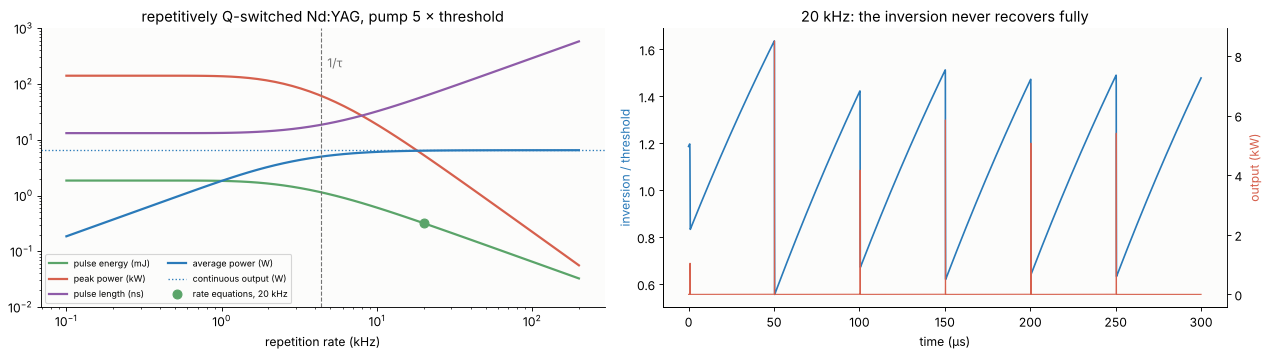

     1 kHz: n_i = 4.94, 1.832 mJ,  138.0 kW peak,  13.3 ns, average 1.83 W
     5 kHz: n_i = 2.98, 1.046 mJ,   52.4 kW peak,  20.0 ns, average 5.23 W
    20 kHz: n_i = 1.49, 0.319 mJ,    5.3 kW peak,  60.0 ns, average 6.38 W
   100 kHz: n_i = 1.09, 0.065 mJ,    0.2 kW peak, 291.9 ns, average 6.50 W
continuous: 6.50 W; rate equations at 20 kHz: 0.322 mJ per pulse


In [4]:
def periodic_n_i(f_rep, r):
    x = r
    for _ in range(200):
        x = r - (r - L.q_switch(x, tau_c)["n_f"])*np.exp(-1/(f_rep*tau))
    return x


f_reps = np.logspace(2, 5.3, 60)
n_is = np.array([periodic_n_i(f, r) for f in f_reps])
qq = L.q_switch(n_is, tau_c)
E_rep = pulse_energy(n_is, qq["n_f"])
P_cw = h_nu*N_th*(r - 1)*tau_c/tau*T_log/T_rt     # continuous output: p = r - 1

# check at 20 kHz with the rate equations over 6 periods
f_chk = 20E3
period = 1/f_chk
t_chk = np.linspace(0, 6*period, 1200001)
open_time = 1E-6
loss_chk = lambda tt: 1.0 if (tt % period) < open_time else q_closed
n_c, p_c = L.rate_equations(t_chk, r, tau, tau_c, beta=1E-9, n0=periodic_n_i(f_chk, r) - 0.3,
                            loss=loss_chk, max_step=1E-9)
P_c = h_nu*p_c*N_th*tau_c/tau*T_log/T_rt
E_last = np.trapezoid(P_c[t_chk > 5*period], t_chk[t_chk > 5*period])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
ax = axes[0]
ax.loglog(f_reps/1E3, E_rep*1E3, color=GREEN, lw=2, label="pulse energy (mJ)")
ax.loglog(f_reps/1E3, peak_power(qq["p_peak"])/1E3, color=RED, lw=2, label="peak power (kW)")
ax.loglog(f_reps/1E3, qq["width"]*1E9, color=PURPLE, lw=2, label="pulse length (ns)")
ax.loglog(f_reps/1E3, E_rep*f_reps, color=BLUE, lw=2, label="average power (W)")
ax.axhline(P_cw, color=BLUE, ls=":", lw=1.2, label="continuous output (W)")
ax.plot(f_chk/1E3, E_last*1E3, "o", color=GREEN, ms=8, label="rate equations, 20 kHz")
ax.axvline(1/tau/1E3, color=GREY, ls="--", lw=1)
ax.text(1/tau/1E3*1.1, 2E2, "1/τ", color=GREY)
ax.set_xlabel("repetition rate (kHz)")
ax.set_title(f"repetitively Q-switched Nd:YAG, pump {r:g} × threshold")
ax.legend(fontsize=8, loc="lower left", ncol=2)
ax.set_ylim(1E-2, 1E3)
ax = axes[1]
ax.plot(t_chk*1E6, n_c, color=BLUE, lw=1.5)
ax2 = ax.twinx()
ax2.plot(t_chk*1E6, P_c/1E3, color=RED, lw=1.0)
ax2.set_ylabel("output (kW)", color=RED); ax2.spines["right"].set_visible(True)
ax.set_xlabel("time (µs)"); ax.set_ylabel("inversion / threshold", color=BLUE)
ax.set_title("20 kHz: the inversion never recovers fully")
plt.tight_layout()
plt.show()
for f in (1E3, 5E3, 20E3, 100E3):
    x = periodic_n_i(f, r)
    q = L.q_switch(x, tau_c)
    print("{:6.0f} kHz: n_i = {:.2f}, {:.3f} mJ, {:6.1f} kW peak, {:5.1f} ns, average {:.2f} W".format(
        f/1E3, x, pulse_energy(x, q["n_f"])*1E3, peak_power(q["p_peak"])/1E3, q["width"]*1E9,
        pulse_energy(x, q["n_f"])*f))
print("continuous: {:.2f} W; rate equations at 20 kHz: {:.3f} mJ per pulse".format(P_cw, E_last*1E3))

At 1 kHz every pulse gets the full 1.8 mJ, but most of the pump is lost
to spontaneous emission between pulses: the average power is 1.8 W, far
below the 6.5 W of continuous operation. At 5 kHz the average power
reaches 80 % of it, at 20 kHz 98 %, but the pulses are weaker and longer,
0.32 mJ and 60 ns at 20 kHz (the rate equations over six periods give the
same energy), 0.07 mJ and 290 ns at 100 kHz.
Marking and micromachining lasers sit in between, at 10 to 100 kHz, with
Nd:YVO₄ (τ = 98 µs) for higher rates; for single high energy pulses, the
pump itself is pulsed for about $\tau$ before each switching.

## 3. Passive Q-switching

A **saturable absorber** in the resonator can do the switching by
itself. A Cr⁴⁺:YAG plate absorbs at 1064 nm with a cross section 15 times
that of Nd:YAG and recovers in 3.4 µs. While the laser is below
threshold it adds its loss; once the gain exceeds the total loss, the first
photons bleach the absorber faster than the gain saturates (because its
cross section is larger), the loss drops, and a giant pulse follows. The
rate equations get a third equation for the fraction $a$ of absorbing ions,

$$\frac{da}{dt} = \frac{1 - a}{\tau_a} - s\,\frac{a\,p}{\tau},$$

with the ratio $s$ of the absorber and gain cross sections (and mode
areas), and the loss becomes $1 + q_a a$. A plate with 90 % single pass
transmission adds $q_a$ = 0.8 to the normalized loss.

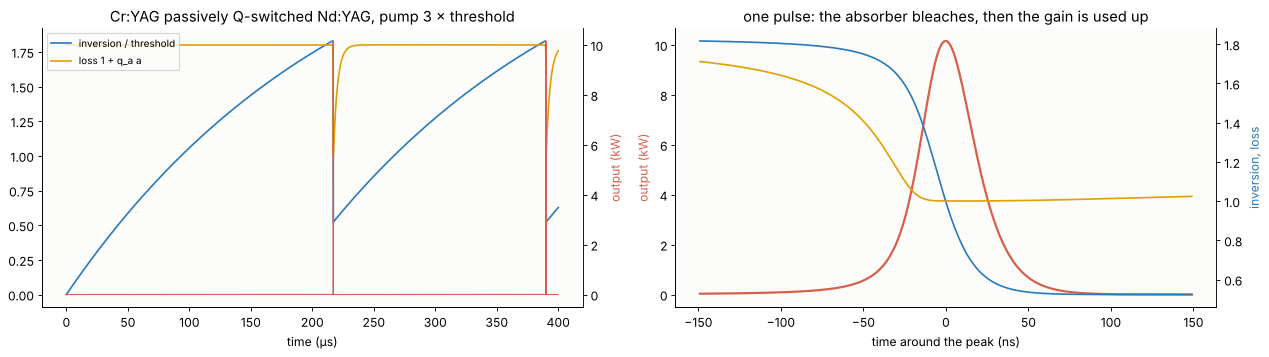

pulses at [217.  390.1] µs, spacing 173 µs; inversion before the pulse 1.83
pulse: 10.16 kW peak, FWHM 38.6 ns, 0.466 mJ; an ideal active switch at the same n_i: 13.24 kW, 0.507 mJ


In [5]:
t_p = np.linspace(0, 400E-6, 400001)
n_p, p_p, a_p = L.rate_equations(t_p, 3.0, tau, tau_c, beta=1E-9, absorber=(0.8, 3.4E-6, 15.0),
                                 max_step=1E-9)
P_p = h_nu*p_p*N_th*tau_c/tau*T_log/T_rt
pk = np.nonzero((p_p[1:-1] > p_p[:-2]) & (p_p[1:-1] > p_p[2:]) & (p_p[1:-1] > 1E2))[0] + 1
k0 = pk[0]
win = (t_p > t_p[k0] - 150E-9) & (t_p < t_p[k0] + 150E-9)
E_pp = np.trapezoid(P_p[win], t_p[win])
n_before = n_p[np.argmin(np.abs(t_p - (t_p[k0] - 1E-6)))]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
ax = axes[0]
ax.plot(t_p*1E6, n_p, color=BLUE, lw=1.5, label="inversion / threshold")
ax.plot(t_p*1E6, 1 + 0.8*a_p, color=ORANGE, lw=1.5, label="loss 1 + q_a a")
ax2 = ax.twinx()
ax2.plot(t_p*1E6, P_p/1E3, color=RED, lw=1.0)
ax2.set_ylabel("output (kW)", color=RED); ax2.spines["right"].set_visible(True)
ax.set_xlabel("time (µs)"); ax.legend(fontsize=9, loc="upper left")
ax.set_title("Cr:YAG passively Q-switched Nd:YAG, pump 3 × threshold")
ax = axes[1]
tt = (t_p[win] - t_p[k0])*1E9
ax.plot(tt, P_p[win]/1E3, color=RED, lw=2, label="output (kW)")
ax2 = ax.twinx()
ax2.plot(tt, n_p[win], color=BLUE, lw=1.5)
ax2.plot(tt, 1 + 0.8*a_p[win], color=ORANGE, lw=1.5)
ax2.set_ylabel("inversion, loss", color=BLUE); ax2.spines["right"].set_visible(True)
ax.set_xlabel("time around the peak (ns)"); ax.set_ylabel("output (kW)", color=RED)
ax.set_title("one pulse: the absorber bleaches, then the gain is used up")
plt.tight_layout()
plt.show()
q_pass = L.q_switch(n_before, tau_c)
print("pulses at {} µs, spacing {:.0f} µs; inversion before the pulse {:.2f}".format(
    np.round(t_p[pk]*1E6, 1), np.diff(t_p[pk]).mean()*1E6, n_before))
print("pulse: {:.2f} kW peak, FWHM {:.1f} ns, {:.3f} mJ; an ideal active switch at the same n_i: {:.2f} kW, {:.3f} mJ".format(
    P_p[k0]/1E3, fwhm(t_p[win], P_p[win])*1E9, E_pp*1E3, peak_power(q_pass["p_peak"])/1E3,
    pulse_energy(n_before, q_pass["n_f"])*1E3))

The passively switched laser fires by itself whenever the inversion
reaches the threshold of the unbleached cavity, 1.8 here, every 173 µs.
The absorber is bleached almost completely during the pulse, so the pulse
is nearly that of an active switch at the same inversion, a little weaker
because the absorber takes its share of the photons. Passive switches are
cheap and need no high voltage, which is why they dominate in microchip
lasers and range finders; their price is a pulse timing that jitters with
the pump (the next pulse fires when the inversion gets there, not when
the user wants it) and an energy fixed by the absorber.

## 4. Mode-locking: phase-locked modes, pulse train and frequency comb

A laser that runs on many longitudinal modes, spaced by
$\Delta\nu = c/2L$, emits their sum. With random phases the modes beat
into a noisy intensity that fluctuates around the mean. If the phases are
locked, the modes add up to a single pulse that repeats every round trip
$T_{rt} = 1/\Delta\nu$: $N$ modes give a peak $N$ times the mean
power and a pulse of about $T_{rt}/N$, the inverse of the locked bandwidth.

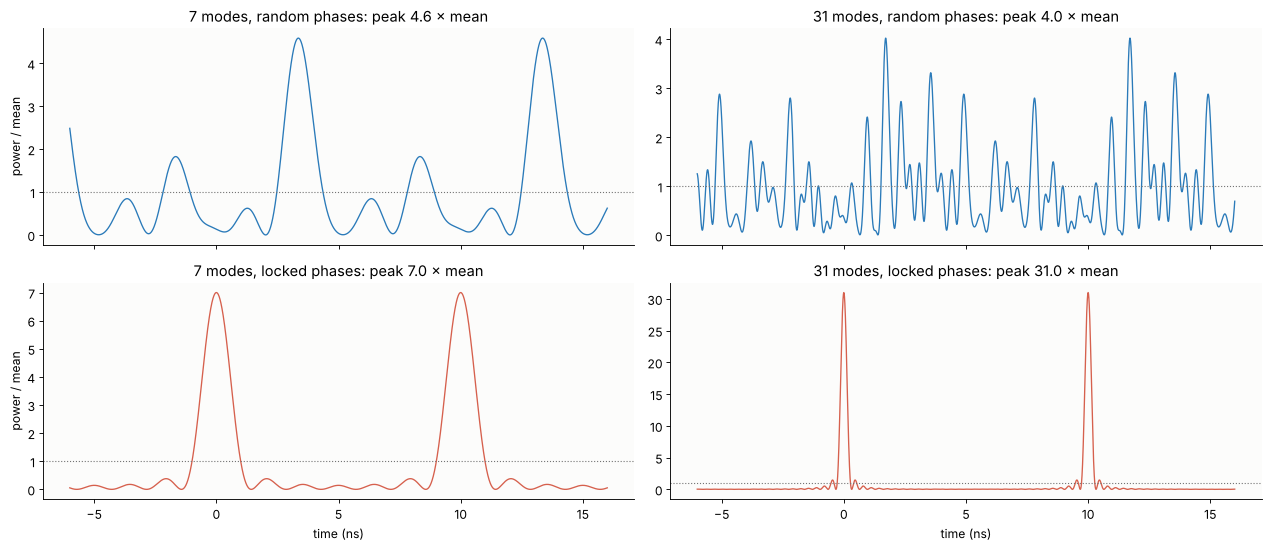

       7 modes of 100 MHz (     0.7 GHz): pulse FWHM 1.27e+03 ps, peak 7e+00 × mean
      31 modes of 100 MHz (     3.1 GHz): pulse FWHM 286 ps, peak 3e+01 × mean
    1000 modes of 100 MHz (     100 GHz): pulse FWHM 8.86 ps, peak 1e+03 × mean
 1000000 modes of 100 MHz (   1e+05 GHz): pulse FWHM 0.00886 ps, peak 1e+06 × mean


In [6]:
fsr = 100E6
t_ml = np.linspace(-0.6/fsr, 1.6/fsr, 8001)
fig, axes = plt.subplots(2, 2, figsize=(16, 7), sharex=True)
for col, N in enumerate((7, 31)):
    for row, ph in enumerate(("random", "locked")):
        A = L.mode_locked_field(t_ml, N, fsr, phases=ph, rng=2)
        ax = axes[row, col]
        ax.plot(t_ml*1E9, np.abs(A)**2/N, color=BLUE if ph == "random" else RED, lw=1.2)
        ax.axhline(1, color=GREY, ls=":", lw=1)
        ax.set_title(f"{N} modes, {ph} phases: peak {np.abs(A).max()**2/N:.1f} × mean")
        if col == 0:
            ax.set_ylabel("power / mean")
for ax in axes[1]:
    ax.set_xlabel("time (ns)")
plt.tight_layout()
plt.show()
for N in (7, 31, 1000, 10**6):
    width = 0.886/(N*fsr)   # FWHM of |sin(N x)/sin(x)|² for large N
    print("{:8d} modes of 100 MHz ({:8.3g} GHz): pulse FWHM {:.3g} ps, peak {:.0e} × mean".format(
        N, N*fsr/1E9, width*1E12, N))

With $N$ = 31 locked modes the laser emits 0.29 ns pulses every 10 ns at
31 times the mean power. Locking the about 10⁶ modes that fit under the
100 THz gain band of Ti:sapphire gives pulses of the order of 10 fs, and
the peak power of a 1 W laser becomes about 1 MW. The pulse duration and
the spectral width are linked by the **time–bandwidth product**: for a
transform limited pulse (no chirp) FWHM duration times FWHM bandwidth is
0.441 for a Gaussian and 0.315 for a sech² shape.

The output is also a **frequency comb**. The envelope repeats every round
trip, but the carrier wave under it advances by the carrier–envelope
phase $\Delta\phi_{ce}$ from pulse to pulse, because group and phase
velocity differ in the resonator. The comb lines are therefore at

$$\nu_n = n f_{rep} + f_{ceo},\qquad f_{ceo} = \frac{\Delta\phi_{ce}}{2\pi}f_{rep},$$

a ruler of optical frequencies with two radio frequencies: counting
$f_{rep}$ and measuring $f_{ceo}$ (by self-referencing an octave wide
spectrum) gives every line to the accuracy of a clock.

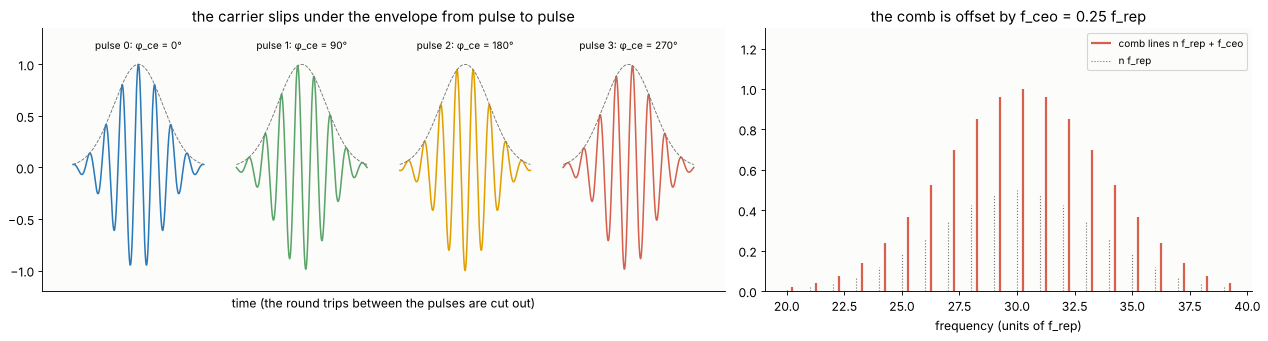

In [7]:
# a toy pulse: 2.5 optical cycles FWHM, carrier envelope phase slip of pi/2 per round trip
cycles, dphi = 2.5, np.pi/2
tau_env = cycles               # in optical periods
tt = np.linspace(-4, 4, 2001)  # optical periods
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
for k, c in enumerate((BLUE, GREEN, ORANGE, RED)):
    env = np.exp(-2*np.log(2)*(tt/tau_env)**2)
    ax.plot(tt + 10*k, env*np.cos(2*np.pi*tt + k*dphi), color=c, lw=1.4)
    ax.plot(tt + 10*k, env, color=GREY, lw=0.8, ls="--")
    ax.text(10*k, 1.15, f"pulse {k}: φ_ce = {k*90}°", ha="center", fontsize=9)
ax.set_xticks([]); ax.set_ylim(-1.2, 1.35)
ax.set_xlabel("time (the round trips between the pulses are cut out)")
ax.set_title("the carrier slips under the envelope from pulse to pulse")
ax = axes[1]
f_rep, f_ceo = 1.0, dphi/(2*np.pi)
nn = np.arange(20, 40)
spec = np.exp(-((nn - 30)/5)**2)
ax.vlines(nn*f_rep + f_ceo, 0, spec, color=RED, lw=2, label="comb lines n f_rep + f_ceo")
ax.vlines(nn*f_rep, 0, spec*0.5, color=GREY, lw=1, ls=":", label="n f_rep")
ax.set_xlabel("frequency (units of f_rep)")
ax.set_title(f"the comb is offset by f_ceo = {f_ceo:.2f} f_rep")
ax.legend(fontsize=9, loc="upper right"); ax.set_ylim(0, 1.3)
plt.tight_layout()
plt.show()

## 5. Active mode-locking

A modulator in the resonator, driven at the round trip frequency, locks
the modes: an acousto-optic modulator (notebook 141, acousto-optics)
whose loss $M(1 - \cos\omega_mt)$ is lowest once per round trip lets the
light that passes at that moment grow, and each pass trims the wings of
the pulse. The gain bandwidth widens the pulse again, because it filters
its spectrum. **Haus's master equation** describes the round trip as a
small change of the envelope $A(t)$,

$$\Delta A = \left[g\left(1 + \frac{1}{\Omega_g^2}\frac{d^2}{dt^2}\right) - l
  - M(1 - \cos\omega_mt)\right]A,$$

and the balance of the parabolic modulation near its minimum and the
parabolic gain filter gives a Gaussian pulse with the Kuizenga–Siegman
length

$$\tau_{FWHM} = 0.446\left(\frac{g}{M}\right)^{1/4}\frac{1}{\sqrt{f_m\Delta\nu_g}}.$$

`L.master_equation()` iterates the round trips in full (gain saturated by
the pulse energy, the gain filter as a Lorentzian, the modulator as a
factor in time), starting from noise.

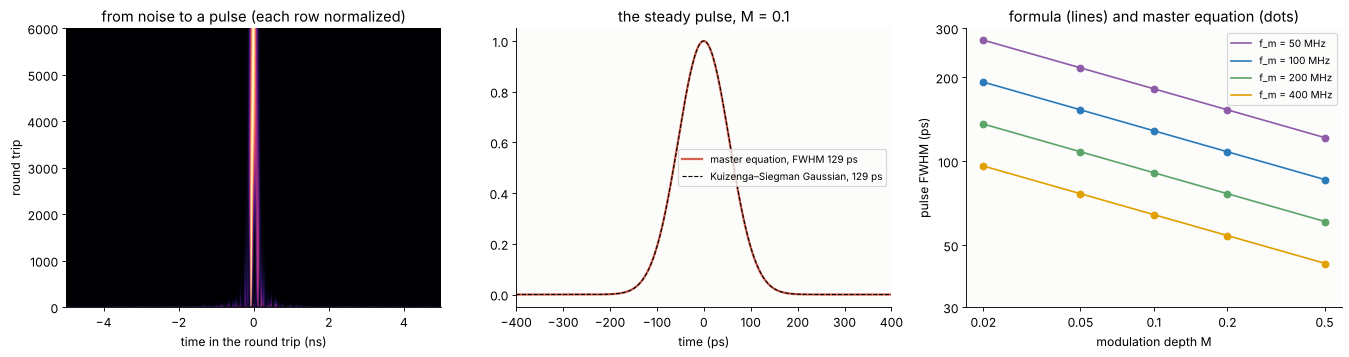

M = 0.1, f_m = 100 MHz: master equation 128.6 ps, Kuizenga-Siegman 128.7 ps, saturated gain 0.1001
time-bandwidth product: 0.441


In [8]:
f_m, dnu_g = 0.1, 120.0            # GHz: 1.5 m cavity, Nd:YAG gain bandwidth; time in ns
t_am = np.linspace(-5, 5, 4096, endpoint=False)
rng = np.random.default_rng(1)
A0 = (rng.standard_normal(len(t_am)) + 1j*rng.standard_normal(len(t_am)))*1E-3
g0, loss = 0.3, 0.1
A_am, hist = L.master_equation(t_am, A0, 20000, g0, 1.0, dnu_g, loss, modulation=(0.1, f_m),
                               record_every=20)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
P_hist = np.abs(hist["fields"])**2
ext = [t_am[0], t_am[-1], 0, len(P_hist)*20]
ax.imshow(P_hist/P_hist.max(axis=1, keepdims=True), aspect="auto", origin="lower", extent=ext, cmap="magma")
ax.set_xlabel("time in the round trip (ns)"); ax.set_ylabel("round trip")
ax.set_title("from noise to a pulse (each row normalized)")
ax.set_ylim(0, 6000)
ax = axes[1]
P_am = np.abs(A_am)**2
w_sim = fwhm(t_am, P_am)
w_ks = L.active_ml_width(hist["gain"][-1], 0.1, f_m*1E9, dnu_g*1E9)*1E9
ax.plot(t_am*1E3, P_am/P_am.max(), color=RED, lw=2, label=f"master equation, FWHM {w_sim*1E3:.0f} ps")
ax.plot(t_am*1E3, np.exp(-4*np.log(2)*(t_am/w_ks)**2), color="k", lw=1, ls="--",
        label=f"Kuizenga–Siegman Gaussian, {w_ks*1E3:.0f} ps")
ax.set_xlim(-400, 400); ax.set_xlabel("time (ps)"); ax.legend(fontsize=9)
ax.set_title("the steady pulse, M = 0.1")
ax = axes[2]
Ms = np.array([0.02, 0.05, 0.1, 0.2, 0.5])
fms = np.array([0.05, 0.1, 0.2, 0.4])
for f_x, c in zip(fms, (PURPLE, BLUE, GREEN, ORANGE)):
    w_s, w_t = [], []
    for M in Ms:
        # start 1.5 times longer than expected, on a window of 16 pulse lengths, and
        # run long enough for the slow modes to decay: the eigenvalue gap of the
        # Gaussian modes is 4 sqrt(g M omega_m**2/2)/Omega_g per round trip
        w0 = L.active_ml_width(loss, M, f_x*1E9, dnu_g*1E9)*1E9
        gap = 4*np.sqrt(loss*M*(2*np.pi*f_x)**2/2)/(np.pi*dnu_g)
        n_rt = int(min(80000, 6/gap))
        half = min(8*w0, 0.5/f_x)
        t_x = np.linspace(-half, half, 1024, endpoint=False)
        A_x, h_x = L.master_equation(t_x, np.exp(-t_x**2/(2*(1.5*w0/1.665)**2)).astype(complex), n_rt, g0,
                                     1.0, dnu_g, loss, modulation=(M, f_x), record_every=n_rt)
        w_s.append(fwhm(t_x, np.abs(A_x)**2))
        w_t.append(L.active_ml_width(h_x["gain"][-1], M, f_x*1E9, dnu_g*1E9)*1E9)
    ax.loglog(Ms, np.array(w_t)*1E3, color=c, lw=1.5, label=f"f_m = {f_x*1E3:.0f} MHz")
    ax.loglog(Ms, np.array(w_s)*1E3, "o", color=c)
ax.set_xlabel("modulation depth M"); ax.set_ylabel("pulse FWHM (ps)")
ax.set_xticks(Ms, [f"{m:g}" for m in Ms]); ax.set_xticks([], minor=True)
ax.set_yticks([30, 50, 100, 200, 300], ["30", "50", "100", "200", "300"]); ax.set_yticks([], minor=True)
ax.set_title("formula (lines) and master equation (dots)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print("M = 0.1, f_m = 100 MHz: master equation {:.1f} ps, Kuizenga-Siegman {:.1f} ps, saturated gain {:.4f}".format(
    w_sim*1E3, w_ks*1E3, hist["gain"][-1]))
print("time-bandwidth product: {:.3f}".format(
    w_sim*fwhm(np.fft.fftshift(np.fft.fftfreq(len(t_am), t_am[1] - t_am[0])),
               np.fft.fftshift(np.abs(np.fft.fft(A_am))**2))))

Starting from noise, the modulator selects one time slot within a few
hundred round trips, and the pulse then shortens slowly over thousands of
round trips to about 130 ps, a transform limited Gaussian
(time–bandwidth product 0.44). Simulation and formula agree within 1 %
over the whole range of modulators, once the pulse has had time to
settle: with a weak modulator at low frequency that takes tens of
thousands of round trips. The pulse length depends only weakly on the
modulator, as $M^{-1/4}$ and $f_m^{-1/2}$: a modulator twice as deep
shortens the pulse by 16 %. Active mode-locking of Nd:YAG and of
diode lasers therefore stops at tens of picoseconds; femtoseconds need a
broader gain and a faster shutter.

## 6. Passive and soliton mode-locking

A **fast saturable absorber** is a shutter that the pulse opens itself,
as fast as the pulse is short: its loss $q_0/(1 + P/P_{sat})$ follows the
instantaneous power. It favours the peak over the wings at every pass,
much more strongly than a modulator, and the pulse shortens until the gain
filter stops it. In Ti:sapphire lasers the fast absorber is the **Kerr
lens**: the intensity dependent index of the crystal focuses the intense
pulse more tightly, and an aperture (or the pump spot) lets the
focused beam pass with less loss. `L.master_equation()` takes the
saturable loss either as $(q_0, P_{sat})$ or as any function of the
power, so that an effective Kerr lens loss can be plugged in.

The self-phase modulation in the crystal ($\delta|A|^2$ per round trip,
with $\delta = 2k_0n_2l/A_{mode}$) and the group delay dispersion
$D$ of the resonator (prisms or chirped mirrors) shape the pulse further:
with negative $D$ they balance like in an optical fibre, and the pulse
becomes a **soliton**, a sech² of length

$$\tau = \frac{2|D|}{\delta E},\qquad \tau_{FWHM} = 1.763\,\tau.$$

The example has the scales of a Ti:sapphire laser: a 2 mm crystal and a
15 µm mode ($\delta$ = 1.33 per MW), 3 % linear loss, 2 % saturable loss
that saturates at 50 kW,
a gain bandwidth limited to 50 THz by the mirrors, and pulse energies of
about 10 nJ. Time is in fs and power in MW, so energies are in nJ.

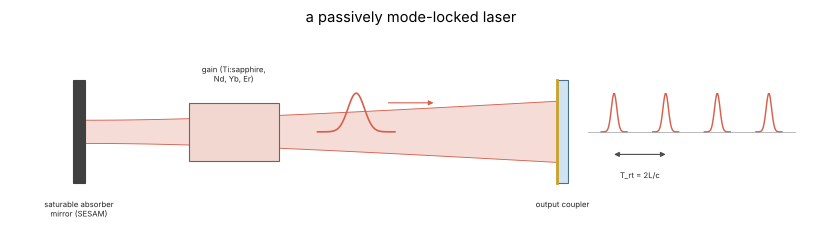

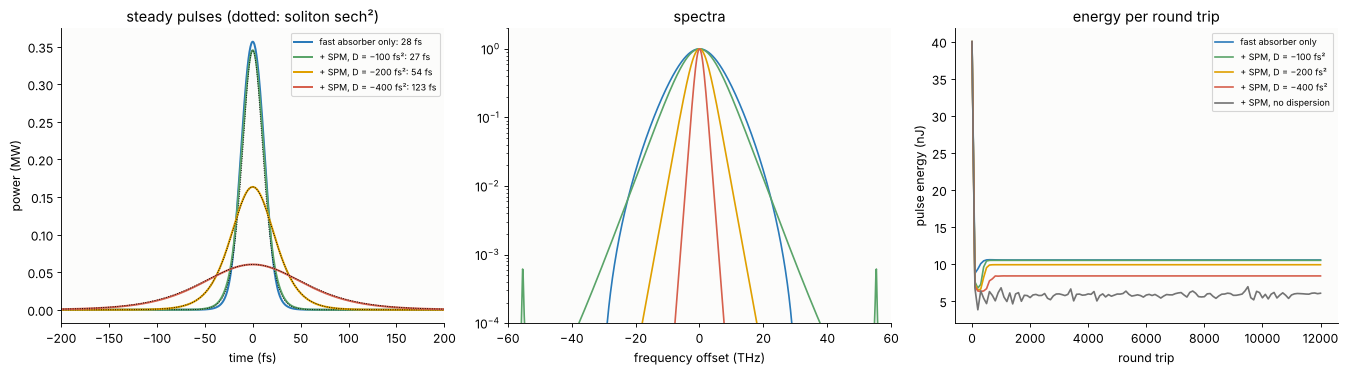

SPM coefficient 1.33 per MW
fast absorber only      : E = 10.55 nJ, FWHM  28.0 fs, time-bandwidth 0.405
+ SPM, D = −100 fs²     : E = 10.51 nJ, FWHM  27.4 fs, soliton formula 25 fs, time-bandwidth 0.337
+ SPM, D = −200 fs²     : E =  9.92 nJ, FWHM  53.7 fs, soliton formula 53 fs, time-bandwidth 0.320
+ SPM, D = −400 fs²     : E =  8.40 nJ, FWHM 122.9 fs, soliton formula 126 fs, time-bandwidth 0.318
+ SPM, no dispersion    : no steady pulse


In [9]:
fig, ax = plt.subplots(figsize=(13, 3.4))
sketch.laser_layout(ax, "mode_locked", title="a passively mode-locked laser")
plt.show()

n2, l_x, w_x, lam = 3E-20, 2E-3, 15E-6, 800E-9
spm = 2*2*np.pi/lam*n2*l_x/(np.pi*w_x**2)*1E6     # per MW
t_fs = np.linspace(-4000, 4000, 2**14, endpoint=False)
dt_fs = t_fs[1] - t_fs[0]
A_start = np.sqrt(0.2)/np.cosh(t_fs/100)
pars = dict(g0=0.1, E_sat=6.0, dnu_g=0.05, loss=0.03, saturable_loss=(0.02, 0.05))
cases_ml = [("fast absorber only", 0.0, 0.0, BLUE),
            ("+ SPM, D = −100 fs²", -100.0, spm, GREEN),
            ("+ SPM, D = −200 fs²", -200.0, spm, ORANGE),
            ("+ SPM, D = −400 fs²", -400.0, spm, RED),
            ("+ SPM, no dispersion", 0.0, spm, GREY)]
results = {}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for name, D, d_spm, c in cases_ml:
    A_ml, h_ml = L.master_equation(t_fs, A_start.astype(complex), 12000, pars["g0"], pars["E_sat"],
                                   pars["dnu_g"], pars["loss"], saturable_loss=pars["saturable_loss"],
                                   gdd=D, spm=d_spm, record_every=100)
    P = np.abs(A_ml)**2
    E = P.sum()*dt_fs
    f = np.fft.fftshift(np.fft.fftfreq(len(t_fs), dt_fs))
    S = np.fft.fftshift(np.abs(np.fft.fft(A_ml))**2)
    stable = np.std(h_ml["energy"][-20:])/np.mean(h_ml["energy"][-20:]) < 1E-6
    w = fwhm(t_fs, P) if stable else np.nan
    results[name] = (E, w, w*fwhm(f, S) if stable else np.nan, stable)
    axes[2].plot(np.arange(len(h_ml["energy"]))*100, h_ml["energy"], color=c, lw=1.5, label=name)
    if stable:
        axes[0].plot(t_fs, P, color=c, lw=1.8, label=f"{name}: {w:.0f} fs")
        axes[1].semilogy(f*1E3, S/S.max(), color=c, lw=1.5)
        if D:
            tau_s = 2*abs(D)/(d_spm*E)
            axes[0].plot(t_fs, P.max()/np.cosh(t_fs/tau_s)**2, color="k", lw=0.8, ls=":")
axes[0].set_xlim(-200, 200); axes[0].set_xlabel("time (fs)"); axes[0].set_ylabel("power (MW)")
axes[0].set_title("steady pulses (dotted: soliton sech²)"); axes[0].legend(fontsize=8)
axes[1].set_xlim(-60, 60); axes[1].set_ylim(1E-4, 2)
axes[1].set_xlabel("frequency offset (THz)"); axes[1].set_title("spectra")
axes[2].set_xlabel("round trip"); axes[2].set_ylabel("pulse energy (nJ)")
axes[2].set_title("energy per round trip"); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("SPM coefficient {:.2f} per MW".format(spm))
for name, D, d_spm, c in cases_ml:
    E, w, tbp, stable = results[name]
    if not stable:
        print("{:24s}: no steady pulse".format(name))
        continue
    pred = "" if not D else ", soliton formula {:.0f} fs".format(1.763*2*abs(D)/(d_spm*E))
    print("{:24s}: E = {:5.2f} nJ, FWHM {:5.1f} fs{}, time-bandwidth {:.3f}".format(name, E, w, pred, tbp))

The fast absorber alone gives a steady pulse of 28 fs whose length is
set by the gain bandwidth. It is unchirped, since gain, filter and
absorber only change amplitudes, but not a sech²: the absorber is
saturated far above $P_{sat}$ and flattens the top, and the
time–bandwidth product is 0.41. With self-phase modulation and negative
dispersion the pulse follows the soliton formula: within 3 % for −200
and −400 fs², where the soliton is longer than what the absorber alone
would make; at −100 fs² the absorber and the gain filter keep it 9 %
above the formula. Twice the dispersion gives twice the length, and an
unchirped sech² again. Self-phase
modulation without dispersion destroys the steady state: the pulse keeps
acquiring chirp and new frequencies that the gain filter cannot remove,
and it breaks up. Real femtosecond lasers therefore balance the
self-phase modulation of the crystal with chirped mirrors or prism pairs,
and choose the dispersion for the desired pulse length. The spikes at
±55 THz in the spectrum of the shortest soliton are **Kelly sidebands**:
dispersive waves that the soliton sheds at each round trip add up where
their phase, $|D|\Omega^2/2$ against the soliton's own
$\delta P_0/2$ per round trip, slips by $2\pi$ (at $\Omega$ = 0.35 rad/fs
for $D$ = −100 fs², 55 THz), a fingerprint of soliton lasers; the shortest
Ti:sapphire lasers reach 5 fs, two optical cycles, with octave spanning
spectra.

## Summary

- **Q-switching:** the inversion stored behind a closed switch leaves in
  one pulse; $n_i - n_f = \ln(n_i/n_f)$, peak photon number
  $N_{th}(n_i - 1 - \ln n_i)$. Nd:YAG: 1.2 mJ, 66 kW, 16 ns from a
  laser that gives 6.5 W continuously.
- **Repetition rate:** above $1/\tau$ the pulses weaken and lengthen
  while the average power approaches the continuous output.
- **Passive Q-switching:** a saturable absorber (Cr:YAG) fires the laser
  at the threshold of the unbleached cavity, with nearly the pulse of an
  active switch and a timing set by the pump.
- **Mode-locking:** $N$ locked modes give pulses $T_{rt}/N$ long and $N$
  times the mean power; the output is a comb $nf_{rep} + f_{ceo}$.
- **Active mode-locking:** Gaussian pulses of
  $0.446(g/M)^{1/4}/\sqrt{f_m\Delta\nu_g}$, about 100 ps for Nd:YAG.
- **Passive and soliton mode-locking:** a fast saturable absorber (a Kerr
  lens) shortens the pulse to the gain bandwidth; negative dispersion and
  self-phase modulation make a sech² soliton of $1.763\cdot2|D|/(\delta E)$.

In [10]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 91 s


## References

- A. E. Siegman, *Lasers*, University Science Books (1986), chapters 25
  to 28.
- W. Koechner, *Solid-State Laser Engineering*, 6th ed., Springer (2006),
  chapters 8 and 9.
- W. G. Wagner and B. A. Lengyel, "Evolution of the giant pulse in a
  laser", J. Appl. Phys. 34, 2040–2046 (1963).
- J. J. Degnan, "Theory of the optimally coupled Q-switched laser", IEEE
  J. Quantum Electron. 25, 214–220 (1989).
- D. J. Kuizenga and A. E. Siegman, "FM and AM mode locking of the
  homogeneous laser", IEEE J. Quantum Electron. 6, 694–708 (1970).
- H. A. Haus, "Mode-locking of lasers", IEEE J. Sel. Top. Quantum
  Electron. 6, 1173–1185 (2000).
- U. Keller, "Recent developments in compact ultrafast lasers", Nature
  424, 831–838 (2003).
- S. T. Cundiff and J. Ye, "Colloquium: Femtosecond optical frequency
  combs", Rev. Mod. Phys. 75, 325–342 (2003).